# Continuous conflict propensity

The paper's main result appears only in a conflict-active subsample (districts with conflict in at least 30% of months), and that cutoff was not chosen in advance. This notebook replaces the sample split with a continuous measure: does the effect of upwind fire become more negative as a district's **conflict propensity** rises?

Propensity is measured two ways:

* **Pre-period propensity** – the share of months with any ACLED event in 2015–2017, with estimation on 2018–2025 only. Propensity is then fixed before any outcome used in estimation. 2015–2017 is used rather than 2015–2016 because ACLED's Indonesia coverage is much thinner before 2018 (333 events in 2017 vs 1,092 in 2018), so a two-year window classifies most districts as zero.
* **Leave-one-year-out propensity** – for each district-year, the share of months with any event in all *other* years. This keeps the full 2015–2025 sample.

The reduced form (conflict on upwind FRP) is the primary specification, as in the paper. It reads the panel written by `wind-IV.ipynb` (`iv_panel_district.csv`).

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import pyfixest as pf
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings('ignore')

ROOT         = str(Path.cwd().resolve().parent)  # repository root; run notebooks from analysis/
PANEL_CSV    = f'{ROOT}/analysis/iv_panel_district.csv'
DISTRICT_SHP = f'{ROOT}/data/administrative/gadm41_IDN_shp/gadm41_IDN_2.shp'
ACLED_XLSX   = f'{ROOT}/data/unrest/ACLED Data_2026-06-10.xlsx'
OUT_CSV      = f'{ROOT}/analysis/output/conflict_propensity_results.csv'
OUT_FIG      = f'{ROOT}/analysis/output/conflict_propensity_bins.png'

INSTR    = ['log_upwind_frp', 'log_upwind_frp_l1']
OUTCOMES = ['events', 'pv_events', 'riots_vac', 'vac']
FE       = 'district + year_month'
VCOV     = {'CRV1': 'province'}

panel = pd.read_csv(PANEL_CSV)
print(f'Panel: {len(panel):,} obs, {panel["district"].nunique()} districts')
print('ACLED events per year:', panel.groupby('year')['events'].sum().to_dict())

Panel: 60,125 obs, 481 districts
ACLED events per year: {2015: 555, 2016: 434, 2017: 333, 2018: 1092, 2019: 1631, 2020: 2012, 2021: 2254, 2022: 3459, 2023: 3581, 2024: 4055, 2025: 2247}


## 1. Event-type outcomes

Riots/VAC and violence against civilians, assigned to districts by coordinates exactly as in `weather-controls.ipynb`, Section 4.

In [2]:
districts_gdf = gpd.read_file(DISTRICT_SHP)[['NAME_1', 'NAME_2', 'geometry']].rename(
    columns={'NAME_1': 'province', 'NAME_2': 'district'})
dup = districts_gdf['district'].duplicated(keep=False)
districts_gdf.loc[dup, 'district'] = (districts_gdf.loc[dup, 'district'] + ' ('
                                      + districts_gdf.loc[dup, 'province'] + ')')

acled = pd.read_excel(ACLED_XLSX, usecols=['event_date', 'event_type', 'latitude', 'longitude'])
acled['event_date'] = pd.to_datetime(acled['event_date'])
acled['year'], acled['month'] = acled['event_date'].dt.year, acled['event_date'].dt.month
ag = gpd.GeoDataFrame(acled, geometry=gpd.points_from_xy(acled['longitude'], acled['latitude']), crs='EPSG:4326')
j = gpd.sjoin(ag, districts_gdf[['district', 'geometry']], how='left', predicate='within')
j = j[~j.index.duplicated(keep='first')]
acled['district'] = j['district'].reindex(acled.index).values
off = acled['district'].isna()
near = gpd.sjoin_nearest(ag.loc[off].to_crs(3395), districts_gdf[['district', 'geometry']].to_crs(3395),
                         how='left', max_distance=20_000)
near = near[~near.index.duplicated(keep='first')]
acled.loc[off, 'district'] = near['district'].reindex(acled.index[off]).values

acled['riots_vac'] = acled['event_type'].isin(['Riots', 'Violence against civilians']).astype(int)
acled['vac'] = (acled['event_type'] == 'Violence against civilians').astype(int)
counts = acled.groupby(['district', 'year', 'month'])[['riots_vac', 'vac']].sum().reset_index()
panel = panel.merge(counts, on=['district', 'year', 'month'], how='left').fillna({'riots_vac': 0, 'vac': 0})
print(panel[OUTCOMES].sum())

events       21653.0
pv_events     3520.0
riots_vac     2824.0
vac           1067.0
dtype: float64


## 2. Propensity measures

Both measures are shares between 0 and 1. In the regressions, the instrument (contemporaneous and lagged) is interacted with propensity. The pre-period measure is fixed within district, so its main effect is absorbed by district fixed effects; the leave-one-year-out measure varies by year, so it enters as a control.

In [3]:
PRE_END = 2017

pre = (panel[panel['year'] <= PRE_END].groupby('district')['events']
       .apply(lambda s: (s > 0).mean()).rename('P'))
est_pre = panel[panel['year'] > PRE_END].merge(pre, on='district')

g = (panel.assign(a=(panel['events'] > 0).astype(int))
          .groupby(['district', 'year'])['a'].agg(['sum', 'count']).reset_index())
tot = g.groupby('district')[['sum', 'count']].transform('sum')
g['P'] = (tot['sum'] - g['sum']) / (tot['count'] - g['count'])
est_loo = panel.merge(g[['district', 'year', 'P']], on=['district', 'year'])

for d in (est_pre, est_loo):
    for z in INSTR:
        d[f'{z}_xP'] = d[z] * d['P']

print(f'Pre-period ({2015}-{PRE_END}) propensity, {pre.size} districts:')
print(pre.describe().round(3))
print(f'Share of districts with zero pre-period events: {(pre == 0).mean():.2f}')
print(f'Estimation sample (pre-period measure): {len(est_pre):,} obs, {est_pre["year"].min()}-{est_pre["year"].max()}')
print(f'Corr(pre-period P, LOO P averaged over years): '
      f'{pre.corr(est_loo.groupby("district")["P"].mean()):.3f}')

Pre-period (2015-2017) propensity, 481 districts:
count    481.000
mean       0.051
std        0.113
min        0.000
25%        0.000
50%        0.000
75%        0.057
max        0.914
Name: P, dtype: float64
Share of districts with zero pre-period events: 0.52
Estimation sample (pre-period measure): 43,290 obs, 2018-2025
Corr(pre-period P, LOO P averaged over years): 0.809


## 3. Linear interaction (reduced form)

$$y_{dt} = \gamma_1 Z_{dt} + \gamma_2 Z_{d,t-1} + \delta_1 (Z_{dt} \times P_d) + \delta_2 (Z_{d,t-1} \times P_d) + \alpha_d + \lambda_t + \varepsilon_{dt}$$

$\delta_1$ is the key coefficient: how much more negative the contemporaneous effect of upwind fire is per unit of propensity (moving from 0% to 100% of months with conflict). The joint test is a Wald test that both interaction terms are zero (province-clustered, $F(2, G-1)$ reference distribution, as for the Anderson–Rubin tests). The implied effect at propensity 0.1, 0.3 and 0.5 is $\gamma_1 + \delta_1 P$.

In [4]:
def joint_p(m, terms, G):
    names = list(m.coef().index)
    idx = [names.index(t) for t in terms]
    b = m.coef()[terms].to_numpy()
    V = m._vcov[np.ix_(idx, idx)]
    W = float(b @ np.linalg.solve(V, b))
    return stats.f.sf(W / len(terms), len(terms), G - 1)

def interaction(data, y, extra='', method='ols'):
    rhs = ' + '.join(INSTR + [f'{z}_xP' for z in INSTR]) + extra
    fit = pf.fepois if method == 'poisson' else pf.feols
    m = fit(f'{y} ~ {rhs} | {FE}', data=data, vcov=VCOV)
    t = m.tidy()
    V = m._vcov
    names = list(m.coef().index)
    i, k = names.index('log_upwind_frp'), names.index('log_upwind_frp_xP')
    g1, d1 = t.loc['log_upwind_frp', 'Estimate'], t.loc['log_upwind_frp_xP', 'Estimate']
    row = {'outcome': y, 'method': method,
           'gamma1': g1, 'gamma1_p': t.loc['log_upwind_frp', 'Pr(>|t|)'],
           'delta1': d1, 'delta1_se': t.loc['log_upwind_frp_xP', 'Std. Error'],
           'delta1_p': t.loc['log_upwind_frp_xP', 'Pr(>|t|)'],
           'joint_interaction_p': joint_p(m, [f'{z}_xP' for z in INSTR], data['province'].nunique())}
    for P in (0.1, 0.3, 0.5):
        eff = g1 + d1 * P
        se = np.sqrt(V[i, i] + P**2 * V[k, k] + 2 * P * V[i, k])
        row[f'effect_P{int(P*100)}'] = eff
        row[f'effect_P{int(P*100)}_p'] = 2 * stats.t.sf(abs(eff / se), data['province'].nunique() - 1)
    return row

rows = []
for label, data, extra in [('pre-period (2015-2017), est. 2018-2025', est_pre, ''),
                           ('leave-one-year-out, 2015-2025', est_loo, ' + P')]:
    print(f'\n== {label} ==')
    for y in OUTCOMES:
        r = interaction(data, y, extra)
        r['measure'] = label
        rows.append(r)
        print(f"  {y:10s} delta1 {r['delta1']:+.4f} (se {r['delta1_se']:.4f}, p={r['delta1_p']:.3f}) | "
              f"joint p={r['joint_interaction_p']:.3f} | effect at P=0.1/0.3/0.5: "
              f"{r['effect_P10']:+.4f}/{r['effect_P30']:+.4f} (p={r['effect_P30_p']:.3f})/{r['effect_P50']:+.4f} (p={r['effect_P50_p']:.3f})")


== pre-period (2015-2017), est. 2018-2025 ==


  events     delta1 -0.1192 (se 0.0710, p=0.103) | joint p=0.160 | effect at P=0.1/0.3/0.5: -0.0121/-0.0359 (p=0.069)/-0.0598 (p=0.082)
  pv_events  delta1 -0.0246 (se 0.0142, p=0.093) | joint p=0.017 | effect at P=0.1/0.3/0.5: -0.0025/-0.0074 (p=0.097)/-0.0124 (p=0.094)
  riots_vac  delta1 -0.0173 (se 0.0119, p=0.154) | joint p=0.005 | effect at P=0.1/0.3/0.5: -0.0018/-0.0052 (p=0.142)/-0.0087 (p=0.145)


  vac        delta1 -0.0098 (se 0.0052, p=0.068) | joint p=0.023 | effect at P=0.1/0.3/0.5: -0.0015/-0.0035 (p=0.058)/-0.0054 (p=0.058)

== leave-one-year-out, 2015-2025 ==
  events     delta1 -0.0441 (se 0.0284, p=0.129) | joint p=0.309 | effect at P=0.1/0.3/0.5: -0.0005/-0.0093 (p=0.050)/-0.0181 (p=0.081)
  pv_events  delta1 -0.0072 (se 0.0053, p=0.183) | joint p=0.051 | effect at P=0.1/0.3/0.5: -0.0004/-0.0019 (p=0.115)/-0.0033 (p=0.139)


  riots_vac  delta1 -0.0089 (se 0.0053, p=0.101) | joint p=0.019 | effect at P=0.1/0.3/0.5: -0.0003/-0.0021 (p=0.076)/-0.0039 (p=0.083)
  vac        delta1 -0.0071 (se 0.0035, p=0.051) | joint p=0.125 | effect at P=0.1/0.3/0.5: -0.0003/-0.0017 (p=0.059)/-0.0031 (p=0.053)


## 4. Poisson interaction (proportional effects)

The linear model measures effects in event counts. High-propensity districts have many more events, so a negative linear interaction could arise mechanically even if fire reduces conflict by the same *percentage* everywhere. The Poisson model measures proportional effects: a negative $\delta_1$ here means the *percentage* effect of upwind fire grows with propensity. Districts with no events in the estimation window drop out (their outcomes are all zero).

In [5]:
for label, data, extra in [('pre-period (2015-2017), est. 2018-2025', est_pre, ''),
                           ('leave-one-year-out, 2015-2025', est_loo, ' + P')]:
    print(f'\n== {label} (Poisson) ==')
    for y in OUTCOMES:
        try:
            r = interaction(data, y, extra, method='poisson')
        except Exception as e:
            print(f'  {y:10s} failed: {e}')
            continue
        r['measure'] = label
        rows.append(r)
        print(f"  {y:10s} gamma1 {r['gamma1']:+.4f} (p={r['gamma1_p']:.3f}) | delta1 {r['delta1']:+.4f} "
              f"(se {r['delta1_se']:.4f}, p={r['delta1_p']:.3f}) | joint p={r['joint_interaction_p']:.3f}")

res = pd.DataFrame(rows)
res.to_csv(OUT_CSV, index=False)
print(f'\nSaved: {OUT_CSV}')


== pre-period (2015-2017), est. 2018-2025 (Poisson) ==
  events     gamma1 -0.0102 (p=0.107) | delta1 +0.0060 (se 0.0112, p=0.595) | joint p=0.664


  pv_events  gamma1 +0.0038 (p=0.755) | delta1 -0.0298 (se 0.0379, p=0.431) | joint p=0.429
  riots_vac  gamma1 +0.0010 (p=0.945) | delta1 -0.0276 (se 0.0438, p=0.529) | joint p=0.627
  vac        gamma1 -0.0297 (p=0.218) | delta1 -0.0240 (se 0.0691, p=0.729) | joint p=0.357

== leave-one-year-out, 2015-2025 (Poisson) ==


  events     gamma1 -0.0087 (p=0.222) | delta1 +0.0067 (se 0.0116, p=0.566) | joint p=0.737
  pv_events  gamma1 +0.0182 (p=0.236) | delta1 -0.0520 (se 0.0389, p=0.181) | joint p=0.378


  riots_vac  gamma1 +0.0161 (p=0.384) | delta1 -0.0597 (se 0.0417, p=0.152) | joint p=0.366
  vac        gamma1 +0.0322 (p=0.284) | delta1 -0.1507 (se 0.0602, p=0.012) | joint p=0.046

Saved: /Users/hariaksha/Documents/GitHub/climate-conflict/analysis/output/conflict_propensity_results.csv


## 5. Binned propensity (no linearity assumption)

Districts are grouped by pre-period propensity. Because 2015–2017 coverage is sparse, many districts have zero pre-period events, and propensity takes only a few distinct values, so the bins are defined by the number of months with any event in 2015–2017 (out of 35 available months): zero, one, two to five, and six or more. The reduced-form coefficient on contemporaneous upwind FRP is estimated separately in each bin (same specification, estimation years 2018–2025). The same exercise is repeated with quintiles of the leave-one-year-out measure averaged within district.

pre-period bin 0 months: 252 districts, propensity 0.000-0.000
pre-period bin 1 month: 100 districts, propensity 0.029-0.029
pre-period bin 2-5 months:  88 districts, propensity 0.057-0.143
pre-period bin 6+ months:  41 districts, propensity 0.171-0.914



Pre-period bins (events):
       bin  n_districts    coef     se      p  mean_events
  0 months          252  0.0025 0.0017 0.1561       0.1777
   1 month          100  0.0026 0.0032 0.4265       0.2831
2-5 months           88 -0.0147 0.0098 0.1443       0.6077
 6+ months           41 -0.0404 0.0178 0.0369       2.4225

Leave-one-year-out quintiles (events):
bin  n_districts    coef     se      p  mean_events
 Q1           98  0.0025 0.0007 0.0026       0.0256
 Q2           96 -0.0029 0.0015 0.0667       0.0732
 Q3           96  0.0042 0.0025 0.1087       0.1463
 Q4           95  0.0002 0.0041 0.9583       0.2709
 Q5           96 -0.0264 0.0065 0.0003       1.2907


Saved: /Users/hariaksha/Documents/GitHub/climate-conflict/analysis/output/conflict_propensity_bins.png


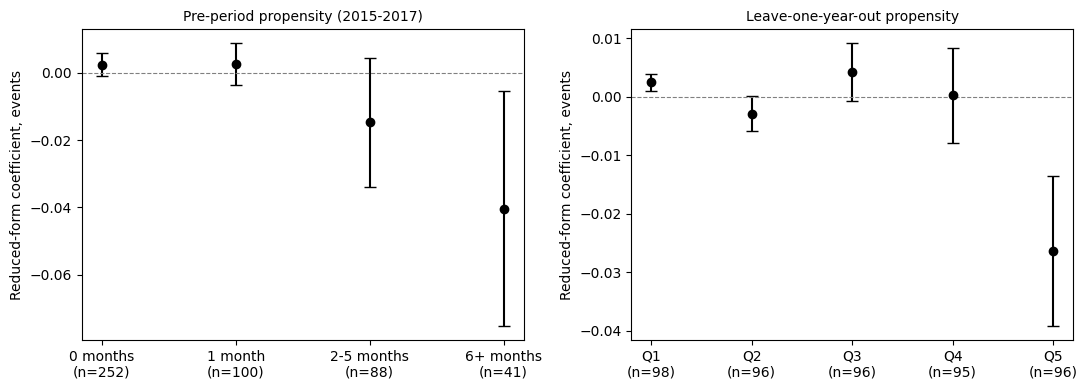

In [6]:
def bin_coefs(data, bins, y='events'):
    out = []
    for b in bins.cat.categories:
        d = data[data['district'].isin(bins[bins == b].index)]
        m = pf.feols(f'{y} ~ {" + ".join(INSTR)} | {FE}', data=d, vcov=VCOV).tidy().loc['log_upwind_frp']
        out.append({'bin': str(b), 'n_districts': int((bins == b).sum()), 'coef': m['Estimate'],
                    'se': m['Std. Error'], 'p': m['Pr(>|t|)'],
                    'mean_events': d[y].mean()})
    return pd.DataFrame(out)

n_pre = (panel[panel['year'] <= PRE_END].groupby('district')['events']
         .apply(lambda s: (s > 0).sum())).reindex(pre.index)
pre_bin = pd.cut(n_pre, [-0.5, 0.5, 1.5, 5.5, np.inf], labels=['0 months', '1 month', '2-5 months', '6+ months'])
for b in pre_bin.cat.categories:
    s = pre[pre_bin == b]
    print(f'pre-period bin {b:6s}: {s.size:3d} districts, propensity {s.min():.3f}-{s.max():.3f}')

loo_mean = est_loo.groupby('district')['P'].mean()
loo_bin = pd.qcut(loo_mean, 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])

bins_pre = bin_coefs(est_pre, pre_bin)
bins_loo = bin_coefs(est_loo, loo_bin)
print('\nPre-period bins (events):'); print(bins_pre.round(4).to_string(index=False))
print('\nLeave-one-year-out quintiles (events):'); print(bins_loo.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, df, title in [(axes[0], bins_pre, 'Pre-period propensity (2015-2017)'),
                      (axes[1], bins_loo, 'Leave-one-year-out propensity')]:
    x = np.arange(len(df))
    ax.errorbar(x, df['coef'], yerr=1.96 * df['se'], fmt='o', capsize=4, color='black')
    ax.axhline(0, color='grey', lw=0.8, ls='--')
    ax.set_xticks(x, [f"{b}\n(n={n})" for b, n in zip(df['bin'], df['n_districts'])])
    ax.set_title(title, fontsize=10)
    ax.set_ylabel('Reduced-form coefficient, events')
fig.tight_layout()
fig.savefig(OUT_FIG, dpi=200)
print(f'Saved: {OUT_FIG}')

## 6. Comparison with the 30% cutoff

For reference: the paper's conflict-active subsample (districts with conflict in at least 30% of months over 2015–2025) gives a reduced-form coefficient on contemporaneous upwind FRP of about −0.026 for events. The implied effects at propensity 0.3 and 0.5 from Section 3 can be compared with that number. Note that the 30% cutoff uses the full-period event share, which is larger than either propensity measure here because conflict reporting grows over time.

In [7]:
full_share = panel.groupby('district')['events'].apply(lambda s: (s > 0).mean())
print('Full-period event share among districts at or above the 30% cutoff, by pre-period bin:')
print(pd.crosstab(pre_bin, full_share.reindex(pre_bin.index) >= 0.30))
print(f'\nCorr(pre-period propensity, full-period event share): {pre.corr(full_share):.3f}')

Full-period event share among districts at or above the 30% cutoff, by pre-period bin:
events      False  True 
events                  
0 months      246      6
1 month        91      9
2-5 months     56     32
6+ months       3     38

Corr(pre-period propensity, full-period event share): 0.809
